# 基於潛在甲基化組分（LMC）之淋巴結轉移預測與臨床存活分析

本筆記本完整重現 6 大 TCGA 實體腫瘤世代（`BLCA`、`BRCA`、`COAD`、`HNSC`、`LUAD`、`STAD`）於兩種去卷積模型架構（共 12 組評估）之懲罰羅吉斯迴歸（L1 / Elastic Net）與臨床存活分層分析：
- **Individual Cancer LMC**（個別癌症專屬 LMC 模型；代表世代 **COAD**，*n* = 194）
- **Pan-Cancer LMC**（跨癌共通 LMC 模型；代表世代 **LUAD**，*n* = 194）

執行全部儲存格後，將依序完成內層 5×5 分層交叉驗證調參、外層留一法交叉驗證（LOOCV）盲測、完整 12 組對齊統計總表（包含原始 `+1.0` 與標準化 `Per-SD` Cox 風險比），以及代表性世代與全世代之 ROC / 風險分佈 / Kaplan–Meier 存活曲線。

## 1. 環境初始化與資料載入

In [1]:
# GitHub repository URL for automatic data cloning in Google Colab
GITHUB_REPO = "https://github.com/Aiorwtlky/LMC-Metastasis-Prediction.git"

import sys
import subprocess
import warnings
import zipfile
from pathlib import Path

try:
    import lifelines
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lifelines"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from scipy.stats import mannwhitneyu
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, LeaveOneOut
from sklearn.metrics import roc_curve, auc
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test

warnings.filterwarnings("ignore")
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["PingFang TC", "STHeiti", "Microsoft JhengHei", "Times New Roman", "DejaVu Serif"]
plt.rcParams["axes.unicode_minus"] = False

def resolve_data_dir():
    for p in [Path("./data"), Path("./LMC-Metastasis-Prediction/data"), Path("./LMC_Metastasis_Prediction/data"), Path("./repo_data/data")]:
        if (p / "sample_list.tsv").exists():
            return p

    if GITHUB_REPO.strip():
        repo_dst = Path("./repo_data")
        if not repo_dst.exists():
            print("Cloning repository data ...")
            subprocess.check_call(["git", "clone", "--depth", "1", GITHUB_REPO.strip(), str(repo_dst)])
        for p in [repo_dst / "data", repo_dst / "LMC_Metastasis_Prediction/data"]:
            if (p / "sample_list.tsv").exists():
                return p

    if "google.colab" in sys.modules:
        from google.colab import files
        print("Upload the dataset archive (lmc_prediction_data.zip) to extract ./data:")
        uploaded = files.upload()
        for fname in uploaded:
            if fname.endswith(".zip"):
                with zipfile.ZipFile(fname, "r") as z:
                    z.extractall(".")
        if (Path("./data") / "sample_list.tsv").exists():
            return Path("./data")

    raise FileNotFoundError(
        "Dataset directory './data' not found. Run inside the repository directory or set GITHUB_REPO."
    )

DATA_DIR = resolve_data_dir()
print(f"Data directory ready: {DATA_DIR.as_posix()}")


Data directory ready: data


## 2. 全六癌別 × 雙模型彈性網調參、LOOCV 盲測與完整 12 組統計總表

In [2]:
CANCERS = ["BLCA", "BRCA", "COAD", "HNSC", "LUAD", "STAD"]
MODEL_CONFIGS = {
    "Individual": {"label": "Individual Cancer LMC", "folder": "cancer-specific_LMC", "suffix": "_proportion.tsv"},
    "Pan_Cancer": {"label": "Pan-Cancer LMC", "folder": "cross-cancer_LMC", "suffix": "_proportion_array.tsv"},
}

def get_stars(p):
    if p < 0.001:
        return " ***"
    if p < 0.01:
        return " **"
    if p < 0.05:
        return " *"
    return ""

def run_cohort_evaluation(cancer, model_type):
    cfg = MODEL_CONFIGS[model_type]
    prop_df = pd.read_csv(DATA_DIR / cfg["folder"] / f"{cancer}{cfg['suffix']}", sep="\t", index_col=0).T
    prop_df.index.name = "sample_id"
    prop_df.reset_index(inplace=True)
    feature_cols = [c for c in prop_df.columns if c != "sample_id"]

    sl = pd.read_csv(DATA_DIR / "sample_list.tsv", sep="\t")
    clin_df = sl[sl["cancer_type"] == cancer].drop_duplicates(subset=["sample_id"])
    surv_df = pd.read_csv(DATA_DIR / "sample_survival" / f"{cancer}_survival.tsv", sep="\t").drop_duplicates(subset=["sample_id"])

    common_ids = set(prop_df["sample_id"]) & set(clin_df["sample_id"]) & set(surv_df["sample_id"])
    merged = (
        prop_df[prop_df["sample_id"].isin(common_ids)]
        .merge(clin_df[["sample_id", "group", "N_status"]], on="sample_id", how="inner")
        .merge(surv_df[["sample_id", "time", "censored"]], on="sample_id", how="inner")
    )
    merged = merged[merged["group"].isin(["N0", "N+"])].copy()
    merged["event_observed"] = ~merged["censored"]

    X = merged[feature_cols]
    y = (merged["group"] == "N+").astype(int)

    # Inner hyperparameter tuning (5x5 repeated stratified CV, zero data leakage)
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LogisticRegression(solver="saga", class_weight="balanced", max_iter=10000, random_state=42)),
    ])
    param_grid = [
        {"lr__penalty": ["l1"], "lr__C": np.logspace(-3, 3, 50)},
        {"lr__penalty": ["elasticnet"], "lr__C": np.logspace(-3, 3, 20), "lr__l1_ratio": np.linspace(0.1, 0.9, 9)},
    ]
    grid = GridSearchCV(pipe, param_grid, cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42),
                        scoring="roc_auc", n_jobs=-1)
    grid.fit(X, y)
    best_pipe = grid.best_estimator_

    # Outer Leave-One-Out Cross-Validation (LOOCV)
    oof_probs = np.zeros(len(y))
    for tr, te in LeaveOneOut().split(X):
        best_pipe.fit(X.iloc[tr], y.iloc[tr])
        oof_probs[te] = best_pipe.predict_proba(X.iloc[te])[:, 1]
    merged["Risk_Score"] = oof_probs

    fpr, tpr, _ = roc_curve(y, oof_probs)
    auroc = float(auc(fpr, tpr))
    _, mw_p = mannwhitneyu(merged[merged["group"] == "N+"]["Risk_Score"],
                           merged[merged["group"] == "N0"]["Risk_Score"], alternative="two-sided")

    T, E = merged["time"], merged["event_observed"]
    med = merged["Risk_Score"].median()
    km50_p = float(logrank_test(T[merged["Risk_Score"] > med], T[merged["Risk_Score"] <= med],
                                event_observed_A=E[merged["Risk_Score"] > med],
                                event_observed_B=E[merged["Risk_Score"] <= med]).p_value)
    q67, q33 = merged["Risk_Score"].quantile(0.67), merged["Risk_Score"].quantile(0.33)
    km33_p = float(logrank_test(T[merged["Risk_Score"] > q67], T[merged["Risk_Score"] < q33],
                                event_observed_A=E[merged["Risk_Score"] > q67],
                                event_observed_B=E[merged["Risk_Score"] < q33]).p_value)

    cph = CoxPHFitter().fit(merged[["time", "event_observed", "Risk_Score"]], duration_col="time", event_col="event_observed")
    cox_p = float(cph.summary.loc["Risk_Score", "p"])
    cox_hr = float(cph.summary.loc["Risk_Score", "exp(coef)"])

    merged["Risk_Z"] = (merged["Risk_Score"] - merged["Risk_Score"].mean()) / merged["Risk_Score"].std()
    cph_z = CoxPHFitter().fit(merged[["time", "event_observed", "Risk_Z"]], duration_col="time", event_col="event_observed")
    cox_hr_sd = float(cph_z.summary.loc["Risk_Z", "exp(coef)"])

    return {
        "cancer": cancer, "model_type": model_type, "model_label": cfg["label"],
        "merged": merged, "fpr": fpr, "tpr": tpr,
        "n0": int((merged["group"] == "N0").sum()), "np": int((merged["group"] == "N+").sum()),
        "auroc": auroc, "mw_p": float(mw_p), "km50_p": km50_p, "km33_p": km33_p,
        "cox_p": cox_p, "cox_hr": cox_hr, "cox_hr_sd": cox_hr_sd,
    }

all_results = {"Individual": [], "Pan_Cancer": []}
for mtype in ["Individual", "Pan_Cancer"]:
    for cancer in CANCERS:
        res = run_cohort_evaluation(cancer, mtype)
        all_results[mtype].append(res)
    all_results[mtype].sort(key=lambda r: r["auroc"], reverse=True)

ordered_rows = all_results["Individual"] + all_results["Pan_Cancer"]
summary_df = pd.DataFrame([
    {
        "Model": r["model_label"],
        "Cancer": r["cancer"],
        "Samples (N0, N+)": f"{r['n0']}, {r['np']}",
        "AUROC": f"{r['auroc']:.4f}",
        "Mann-Whitney P": "< 0.001 ***" if r["mw_p"] < 0.001 else f"{r['mw_p']:.4f}{get_stars(r['mw_p'])}",
        "KM Median P (50%)": f"{r['km50_p']:.4f}{get_stars(r['km50_p'])}",
        "KM Tertile P (33%)": f"{r['km33_p']:.4f}{get_stars(r['km33_p'])}",
        "Cox P": f"{r['cox_p']:.4f}{get_stars(r['cox_p'])}",
        "Cox HR (Raw +1.0)": f"{r['cox_hr']:.2f}",
        "Cox HR (Per-SD)": f"{r['cox_hr_sd']:.2f}",
    }
    for r in ordered_rows
])

class _AlignedSummaryTable:
    def __init__(self, df):
        cols = list(df.columns)
        th = "".join(
            f"<th style='padding:8px 11px;text-align:{'left' if i == 0 else 'center'};border-top:2px solid #000;border-bottom:1.5px solid #000;white-space:nowrap;font-weight:700;'>{c}</th>"
            for i, c in enumerate(cols)
        )
        rows = []
        for r_i, (_, row) in enumerate(df.iterrows()):
            top_sep = "border-top:1px solid #888;" if r_i == 6 else ""
            bot_sep = "border-bottom:2px solid #000;" if r_i == len(df) - 1 else ""
            tds = "".join(
                f"<td style='padding:6px 11px;text-align:{'left' if i == 0 else 'center'};{top_sep}{bot_sep}white-space:nowrap;font-weight:{'600' if (i == 1 or '*' in str(row[c])) else '400'};'>{row[c]}</td>"
                for i, c in enumerate(cols)
            )
            rows.append(f"<tr>{tds}</tr>")
        self._html = (
            "<table style='border-collapse:collapse;font-family:Arial,sans-serif;font-size:13px;margin:8px 0;background:transparent;'>"
            f"<thead><tr>{th}</tr></thead><tbody>{''.join(rows)}</tbody></table>"
        )
        self._plain_text = df.to_string(index=False)

    def _repr_html_(self):
        return self._html

    def __repr__(self):
        return self._plain_text

_AlignedSummaryTable(summary_df)


Model,Cancer,"Samples (N0, N+)",AUROC,Mann-Whitney P,KM Median P (50%),KM Tertile P (33%),Cox P,Cox HR (Raw +1.0),Cox HR (Per-SD)
Individual Cancer LMC,COAD,"96, 98",0.7209,< 0.001 ***,0.1852,0.0345 *,0.1545,2.56,1.20
Individual Cancer LMC,BRCA,"99, 97",0.6498,< 0.001 ***,0.1601,0.2378,0.2758,1051.46,1.28
Individual Cancer LMC,HNSC,"99, 100",0.6183,0.0040 **,0.0283 *,0.0057 **,0.0681,6.88,1.21
Individual Cancer LMC,BLCA,"100, 97",0.6107,0.0073 **,0.6908,0.6119,0.2004,2.94,1.14
Individual Cancer LMC,LUAD,"98, 97",0.5673,0.1046,0.3313,0.7381,0.9142,0.77,0.99
Individual Cancer LMC,STAD,"96, 96",0.5323,0.4397,0.2395,0.1711,0.1250,957.16,1.23
Pan-Cancer LMC,LUAD,"97, 97",0.7105,< 0.001 ***,0.0080 **,0.0168 *,0.0002 ***,142.56,1.59
Pan-Cancer LMC,HNSC,"100, 100",0.6877,< 0.001 ***,0.0482 *,0.0633,0.0912,2.59,1.21
Pan-Cancer LMC,BLCA,"100, 98",0.6364,< 0.001 ***,0.6855,0.1740,0.1381,2.87,1.17
Pan-Cancer LMC,STAD,"96, 96",0.6243,0.0029 **,0.2007,0.5989,0.4159,2.06,1.10


## 3. 代表性世代視覺化（COAD 個別癌症 LMC & LUAD 跨癌共通 LMC）

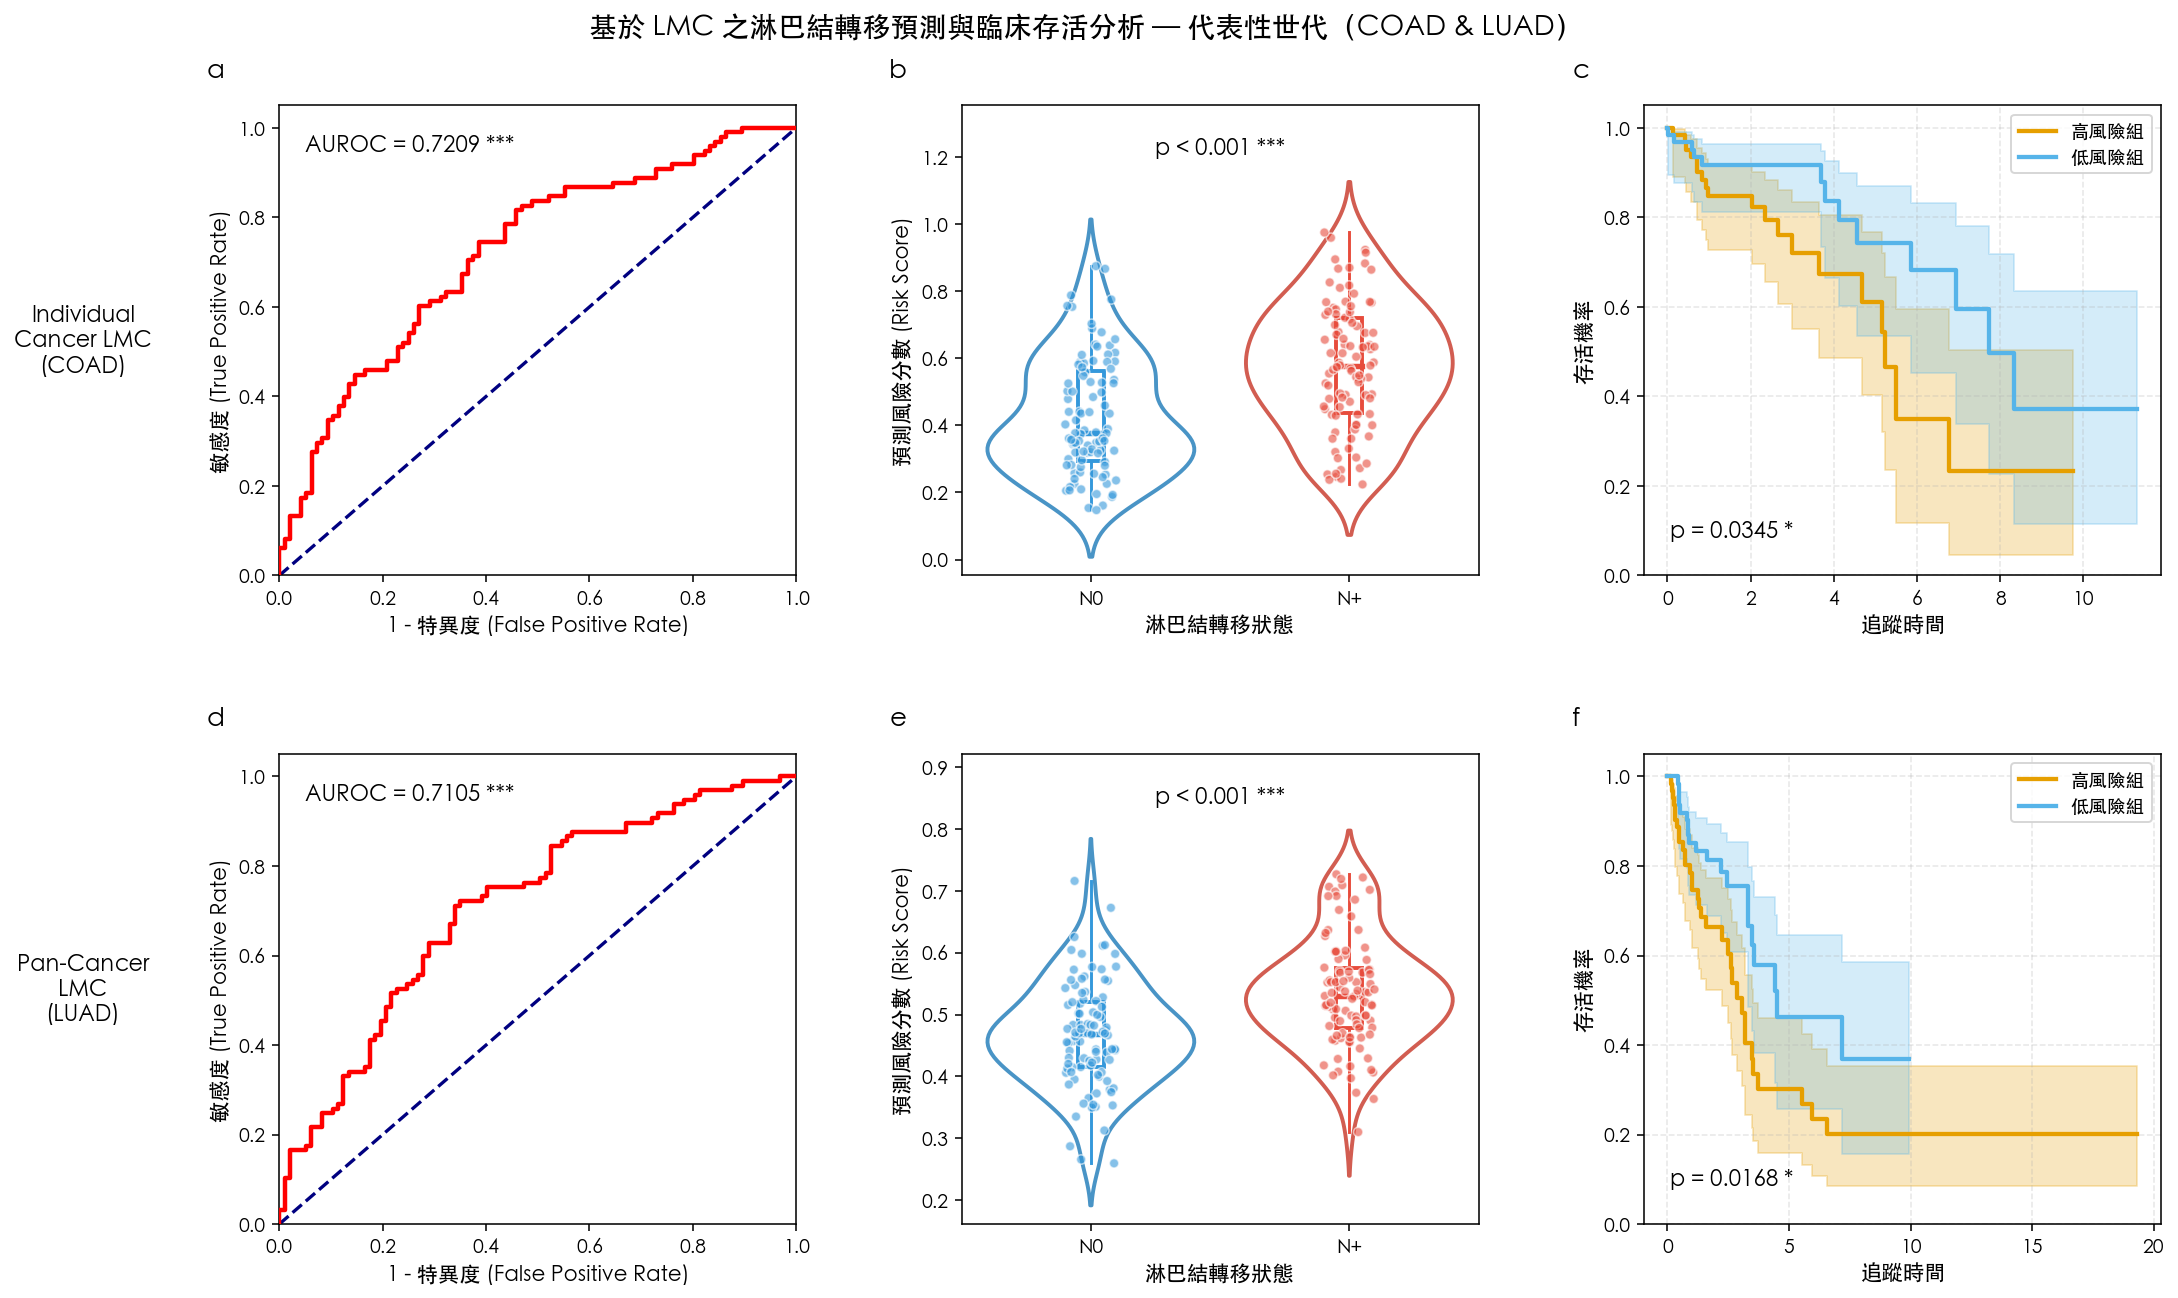

In [3]:
def plot_cohort_grid(results_list, suptitle_txt, panel_letters=None):
    n_rows = len(results_list)
    fig, axs = plt.subplots(n_rows, 3, figsize=(16.0, 4.4 * n_rows + 0.6), dpi=140, squeeze=False)
    top_pad = 0.90 if n_rows == 2 else 0.96
    plt.subplots_adjust(hspace=0.38, wspace=0.32, top=top_pad, bottom=0.05, left=0.14, right=0.98)

    for row_idx, res in enumerate(results_list):
        merged = res["merged"]
        lbl_text = res["model_label"].replace(" ", "\n", 1) + f"\n({res['cancer']})"
        axs[row_idx, 0].text(-0.38, 0.50, lbl_text,
                             transform=axs[row_idx, 0].transAxes, fontsize=11.5, fontweight="bold", ha="center", va="center")

        # ROC Curve
        ax = axs[row_idx, 0]
        if panel_letters:
            ax.text(-0.14, 1.05, panel_letters[row_idx][0], transform=ax.transAxes, fontsize=13.5, fontweight="bold", va="bottom", ha="left")
        ax.plot(res["fpr"], res["tpr"], color="red", lw=2.3, zorder=3)
        ax.plot([0, 1], [0, 1], color="navy", lw=1.7, linestyle="--", zorder=2)
        ax.set_xlim([0, 1]); ax.set_ylim([0, 1.05])
        ax.set_xlabel("1 - 特異度 (False Positive Rate)", fontsize=11, fontweight="bold")
        ax.set_ylabel("敏感度 (True Positive Rate)", fontsize=11, fontweight="bold")
        ax.text(0.05, 0.90, f"AUROC = {res['auroc']:.4f}{get_stars(res['mw_p'])}", transform=ax.transAxes, fontsize=11.5, fontweight="bold")

        # Binary Risk Score Violin Plot
        ax = axs[row_idx, 1]
        if panel_letters:
            ax.text(-0.14, 1.05, panel_letters[row_idx][1], transform=ax.transAxes, fontsize=13.5, fontweight="bold", va="bottom", ha="left")
        palette = {"N0": "#3498db", "N+": "#e74c3c"}
        sns.violinplot(x="group", y="Risk_Score", data=merged, inner=None, palette=palette, order=["N0", "N+"], hue="group", legend=False, ax=ax)
        for v in ax.collections:
            orig = v.get_facecolor()
            if len(orig) > 0:
                v.set_edgecolor(orig[0])
            v.set_facecolor("none"); v.set_linewidth(2.0)
        for j, grp in enumerate(["N0", "N+"]):
            sc = merged[merged["group"] == grp]["Risk_Score"].dropna()
            q1, med, q3 = np.percentile(sc, [25, 50, 75])
            ax.plot([j, j], [np.min(sc), q1], color=palette[grp], lw=1.5)
            ax.plot([j, j], [q3, np.max(sc)], color=palette[grp], lw=1.5)
            ax.add_patch(patches.Rectangle((j - 0.05, q1), 0.10, q3 - q1, facecolor="white", edgecolor=palette[grp], lw=2.0, zorder=3))
            ax.plot([j - 0.05, j + 0.05], [med, med], color=palette[grp], lw=2.8, zorder=4)
        np.random.seed(42)
        sns.stripplot(x="group", y="Risk_Score", data=merged, size=4.8, jitter=True, palette=palette, edgecolor="white", linewidth=0.8,
                      order=["N0", "N+"], hue="group", legend=False, alpha=0.6, zorder=5, ax=ax)
        ymin, ymax = ax.get_ylim(); ax.set_ylim([ymin, ymax + 0.14 * (ymax - ymin)])
        ax.set_xlabel("淋巴結轉移狀態", fontsize=11, fontweight="bold")
        ax.set_ylabel("預測風險分數 (Risk Score)", fontsize=11, fontweight="bold")
        ax.text(0.50, 0.91, "p < 0.001 ***" if res["mw_p"] < 0.001 else f"p = {res['mw_p']:.4f}{get_stars(res['mw_p'])}",
                transform=ax.transAxes, fontsize=11.5, fontweight="bold", ha="center", va="center")

        # Kaplan-Meier Extreme Tertile (Top vs. Bottom 33%)
        ax = axs[row_idx, 2]
        if panel_letters:
            ax.text(-0.14, 1.05, panel_letters[row_idx][2], transform=ax.transAxes, fontsize=13.5, fontweight="bold", va="bottom", ha="left")
        T, E = merged["time"], merged["event_observed"]
        q67, q33 = merged["Risk_Score"].quantile(0.67), merged["Risk_Score"].quantile(0.33)
        kmf_h, kmf_l = KaplanMeierFitter(), KaplanMeierFitter()
        kmf_h.fit(T[merged["Risk_Score"] > q67], event_observed=E[merged["Risk_Score"] > q67], label="高風險組")
        kmf_h.plot_survival_function(ax=ax, color="#E69F00", ci_show=True, lw=2.2)
        kmf_l.fit(T[merged["Risk_Score"] < q33], event_observed=E[merged["Risk_Score"] < q33], label="低風險組")
        kmf_l.plot_survival_function(ax=ax, color="#56B4E9", ci_show=True, lw=2.2)
        ax.set_ylim([0, 1.05]); ax.grid(True, alpha=0.3, linestyle="--")
        ax.set_xlabel("追蹤時間", fontsize=11, fontweight="bold")
        ax.set_ylabel("存活機率", fontsize=11, fontweight="bold")
        ax.legend(loc="upper right", fontsize=9.5, frameon=True, facecolor="white")
        ax.text(0.05, 0.08, f"p = {res['km33_p']:.4f}{get_stars(res['km33_p'])}", transform=ax.transAxes, fontsize=11.5, fontweight="bold")

    fig.suptitle(suptitle_txt, fontsize=14.5, fontweight="bold", y=0.985 if n_rows > 2 else 0.97)
    plt.show()

res_coad = next(r for r in all_results["Individual"] if r["cancer"] == "COAD")
res_luad = next(r for r in all_results["Pan_Cancer"] if r["cancer"] == "LUAD")
plot_cohort_grid([res_coad, res_luad], "基於 LMC 之淋巴結轉移預測與臨床存活分析 — 代表性世代（COAD & LUAD）", panel_letters=[["a", "b", "c"], ["d", "e", "f"]])


## 4. 全六癌別世代完整驗證曲線（Individual & Pan-Cancer LMC）

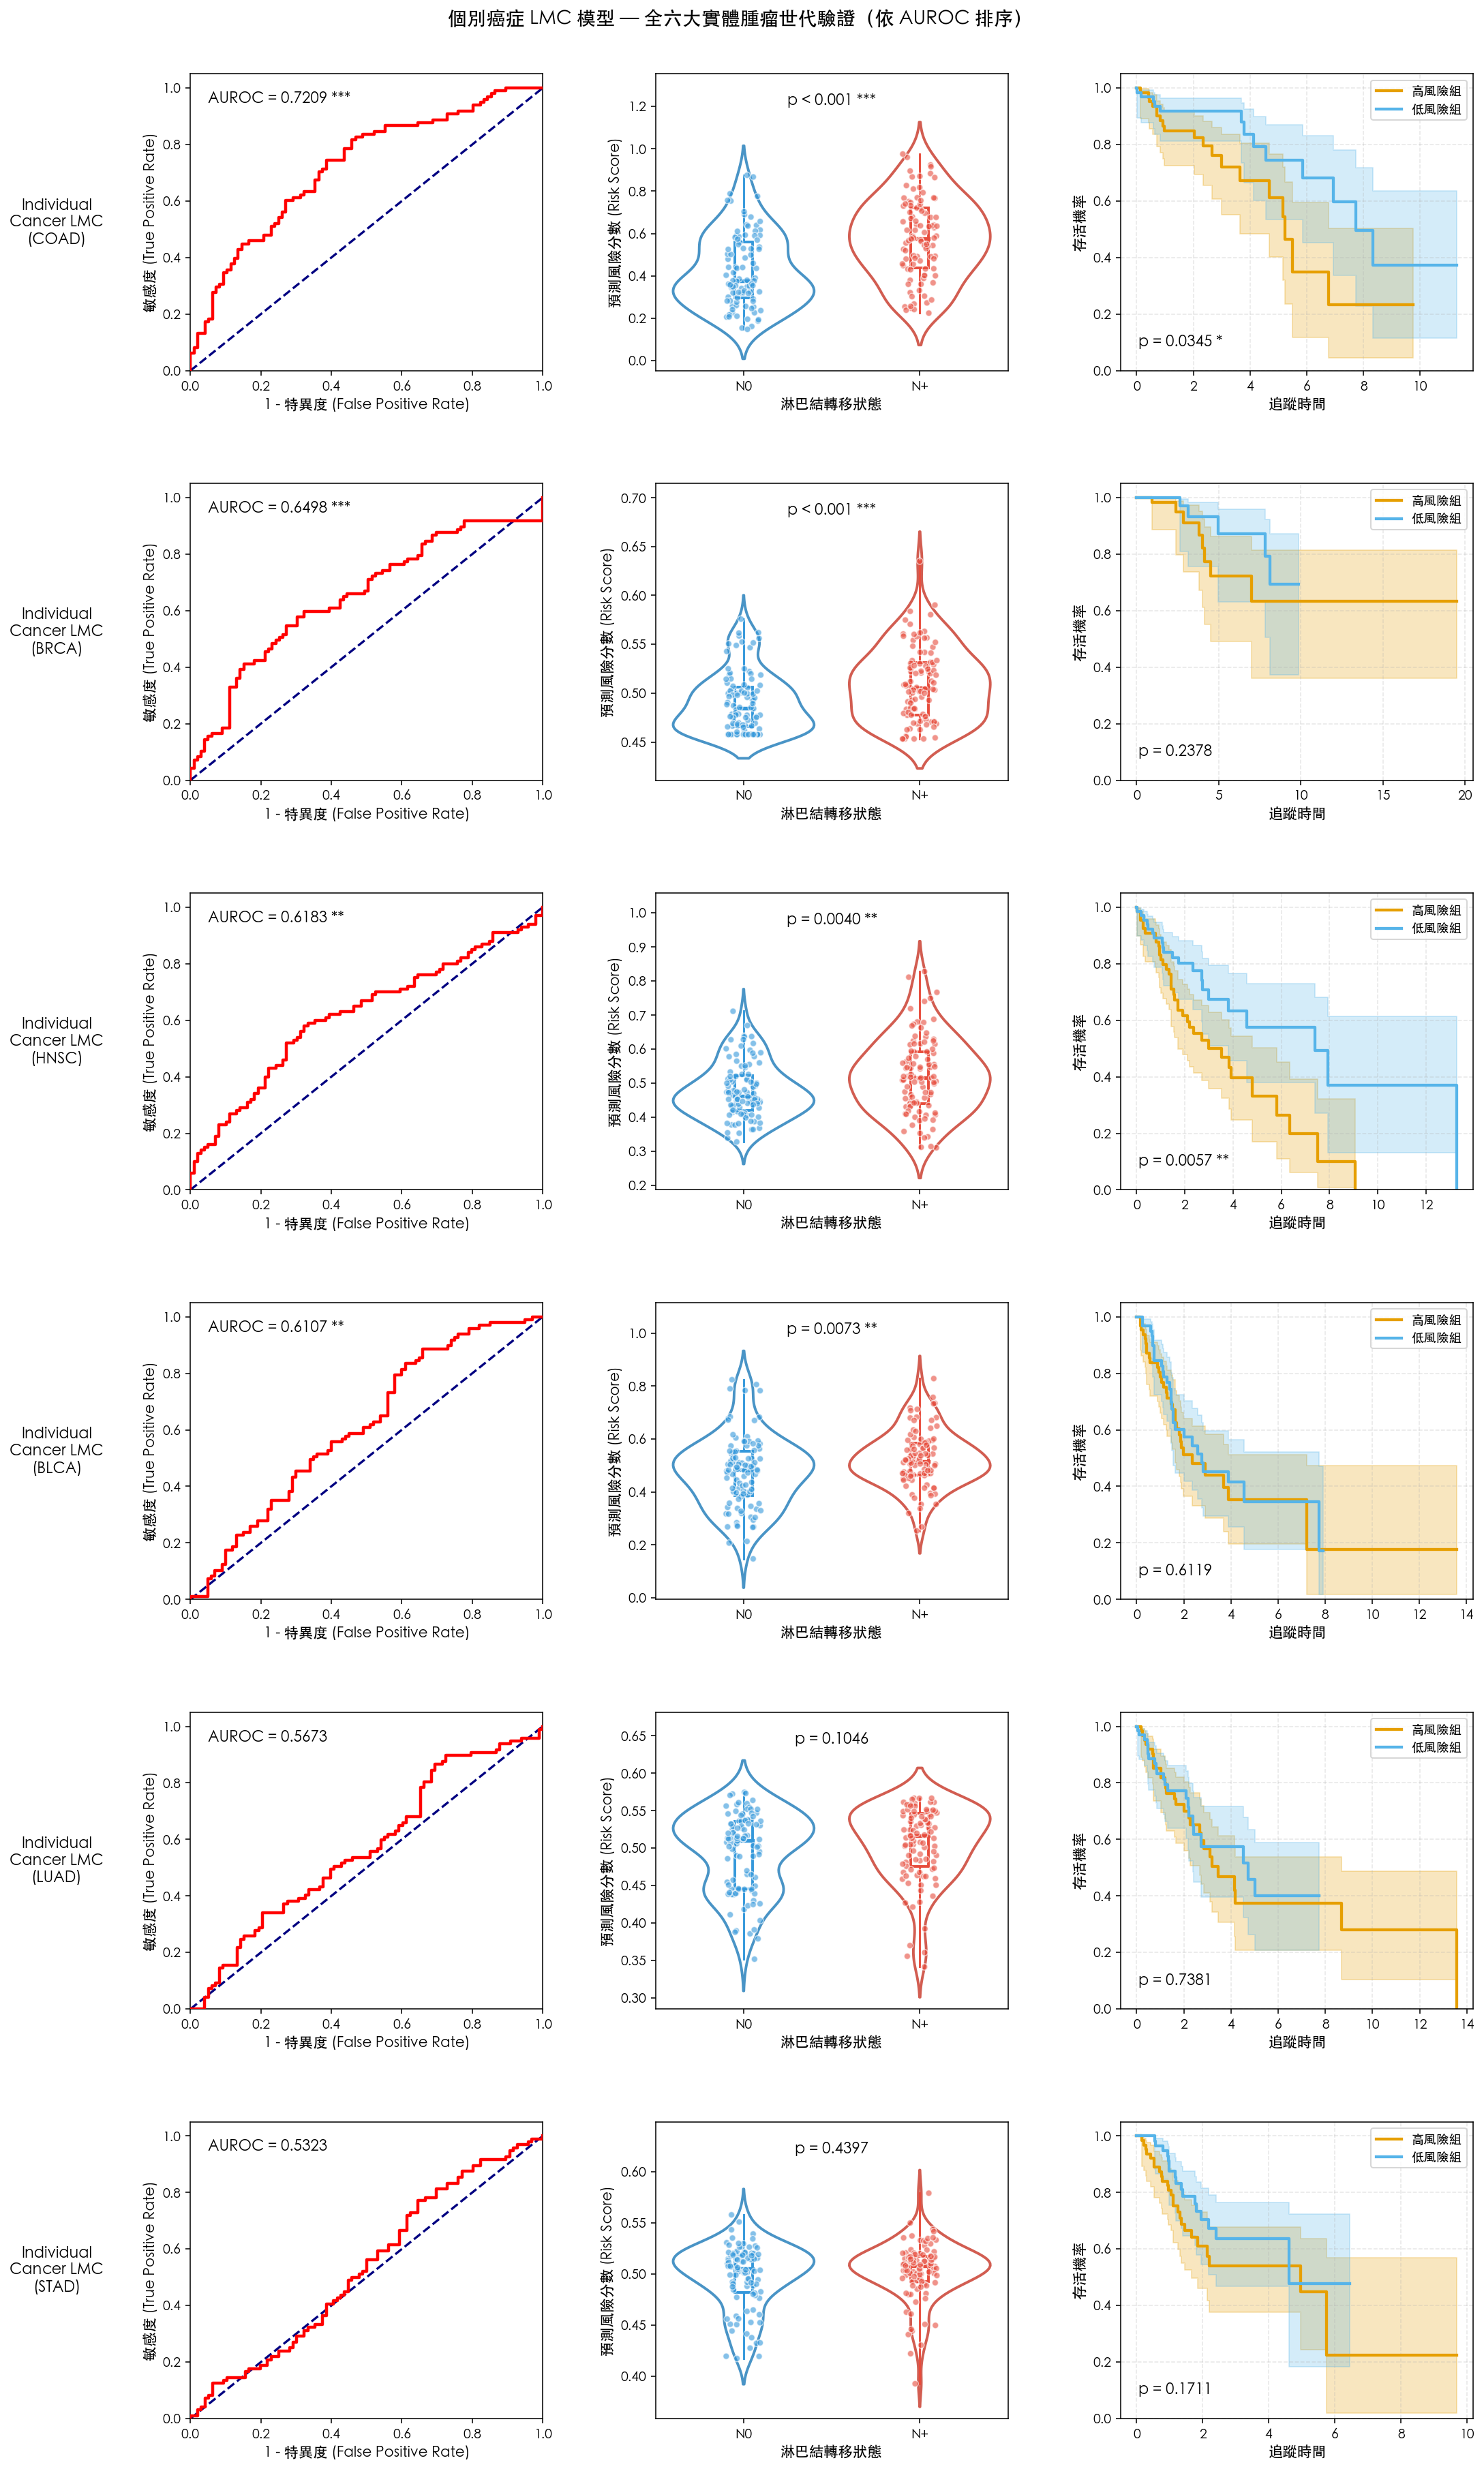

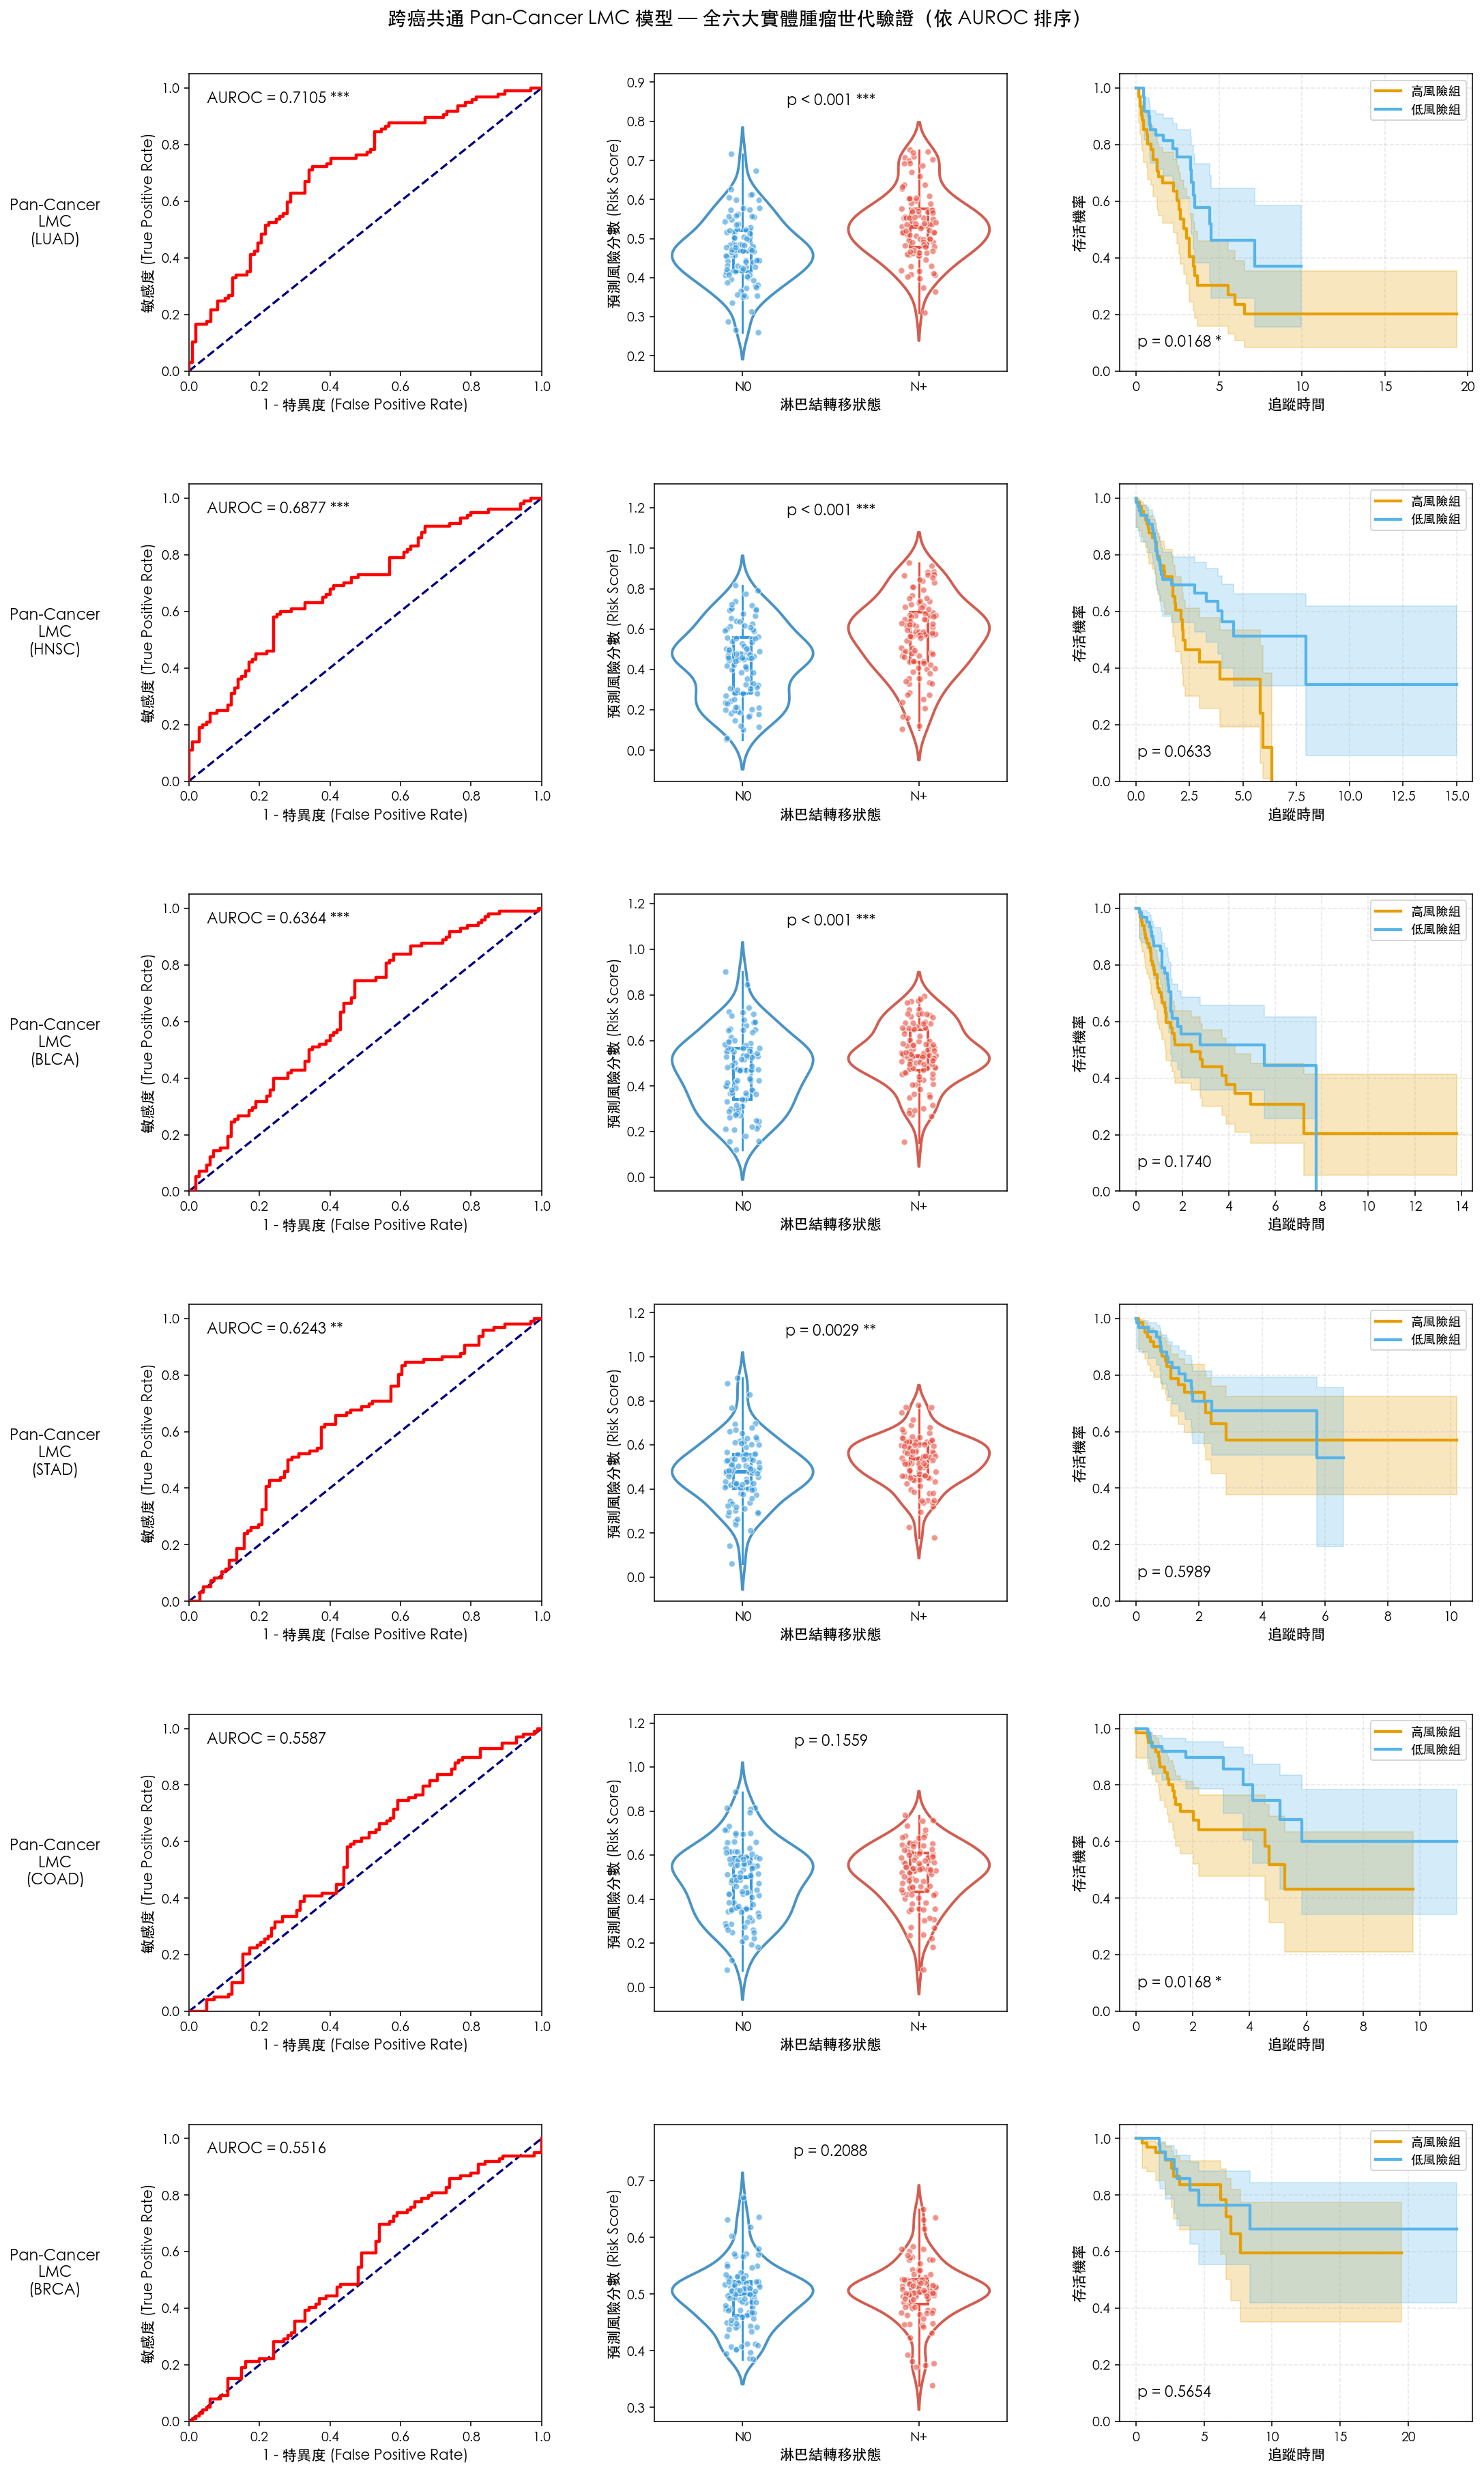

In [4]:
plot_cohort_grid(all_results["Individual"], "個別癌症 LMC 模型 — 全六大實體腫瘤世代驗證（依 AUROC 排序）")
plot_cohort_grid(all_results["Pan_Cancer"], "跨癌共通 Pan-Cancer LMC 模型 — 全六大實體腫瘤世代驗證（依 AUROC 排序）")
